# N138 interpretation: the apparent gain depends on the reader

The completed crossed audit used seven saved encoders, zero SSL updates and no
optimizer. Both original audit recipes reproduce within the locked tolerances.
No support/query overlap was found in any crossed condition. Five targeted
tests and GPU feature/state checks pass. Independent reconstruction verifies all
56 saved conditions and exact support-only scalers; source/model/feature hashes
remain unchanged. N137 remains stopped.

The primary comparison is N137 conservative family 5003 versus its frozen parent.
All four cells below use the same float64 C=1, fifty-label refitted probe recipe:

| Probe support | Historical queries | Modern queries |
|---|---:|---:|
| Historical | **+2.83 pp** | **+0.85 pp** |
| Modern | **-1.90 pp** | **-0.52 pp** |

Changing support source reverses the sign on BOTH query panels. Changing query
population alone reduces the historical-support gain, but does not reverse it
for this encoder. The historical-versus-modern discrepancy therefore cannot be
attributed solely to harder queries, weather or a universally better encoder.
This is an interaction between the changed representation and the labeled
examples used to fit a small downstream reader.

The modern-minus-historical support effect on the parent-relative gain is
-4.73 pp on historical queries (descriptive query 95% interval [-7.63, -1.83])
and -1.36 pp on modern queries ([-2.08, -0.63]). These intervals hold the support
readers/models fixed and are not evidence across independent training seeds.

The modern primary point difference itself is not a decisive loss: -0.52 pp
has query interval [-1.04, +0.02]. Seven of twelve modern readers improve,
with median change +0.095 pp. One reader loses 6.41 pp; leaving that reader out
would change the mean to +0.018 pp. This post-hoc diagnostic shows reader
sensitivity; the declared twelve-reader mean remains -0.52 pp. Do not discard
the unfavorable reader or promote the leave-one-out mean as the result.

The pattern is not identical for all controllers. Archived N101 improves
2.75 pp with historical support AND historical queries, but loses 0.88 pp
when its historical-support readers are tested on modern queries. Modern
support gives -1.19 pp on historical and -1.03 pp on modern queries. Thus the
original N101 result depends on query population as well as support choice;
the primary N137 support finding is not a universal explanation for every MPC.

Keeping parent heads/scalers fixed instead of refitting them produces losses
of 7.34 to 12.54 pp for N137 across the four crossings, including -11.45 pp on
the modern diagonal. Encoder adaptation strongly disrupts existing reader
compatibility. This can include coordinate/scale changes that are recoverable
by refitting; it is NOT proof that all this information was semantically lost.
The refitted modern panel still trades city accuracy (-6.08 pp, averaging light
conditions) for highway accuracy (+5.04 pp). All four refitted comparisons
improve CE, so accuracy, confidence and compatibility tell different stories.

The numerical issue found during reproduction is separate: native historical
float32 probabilities can saturate at zero/one and inflate clipped CE. We kept
the failed parent check, reproduced native arithmetic separately, and used
uniform float64 in all crossings. This explains the small difference between
the +3.00 pp original N137 historical gain and +2.83 pp in the common recipe;
it does not explain the several-point support/query interactions.

Implication: retain the historical improvement as conditional few-label
readout evidence. It does not establish broad semantic retention. Before
another long controller run, qualify a retention instrument against both
refitted-reader accessibility and fixed-reader compatibility, and report
multiple fixed support sets and each city/highway-light cell. No reconstruction,
rank or feature-drift proxy becomes validated by these results alone.

This is an exploratory analysis on reused panels and one pretrained parent.
Marginal query intervals do not cover support-population uncertainty, unknown
cross-drive session dependence, multiple comparisons or independent training
variation. The partial N137 N101 checkpoint is diagnostic, never a matched
full endpoint. A genuinely unused panel is still needed for later confirmation.


# N138 — crossed audit transfer

Stage: **complete**. Zero SSL updates; saved encoders only.

Primary contrast: completed N137 conservative family 5003 minus the common frozen parent.

| Model | Historical support / historical queries | Historical support / modern queries | Modern support / historical queries | Modern support / modern queries |
|---|---:|---:|---:|---:|
| parent | 60.667% | 60.166% | 62.604% | 63.024% |
| N101 | 63.417% | 59.287% | 61.417% | 61.990% |
| N105_current_J | 62.833% | 60.132% | 59.625% | 61.630% |
| N135_mpc | 58.667% | 56.192% | 59.188% | 59.911% |
| N135_paced_quarter | 61.333% | 58.707% | 59.104% | 61.429% |
| N137_conservative | 63.500% | 61.013% | 60.708% | 62.506% |
| N137_n101_partial_53760 | 63.417% | 60.670% | 61.438% | 62.055% |

## Primary changes relative to parent

| Reader mode | Support | Queries | Accuracy change pp [95% query interval] | CE change |
|---|---|---|---:|---:|
| refit | historical | historical | +2.833 [+0.083, +5.583] | -0.21487 |
| refit | historical | modern | +0.846 [+0.194, +1.538] | -0.12203 |
| refit | modern | historical | -1.896 [-3.917, -0.021] | -0.11978 |
| refit | modern | modern | -0.518 [-1.043, +0.015] | -0.07191 |
| fixed_parent | historical | historical | -11.583 [-15.250, -7.750] | +10.07186 |
| fixed_parent | historical | modern | -7.342 [-8.369, -6.346] | +9.19558 |
| fixed_parent | modern | historical | -12.542 [-16.417, -8.792] | +6.97784 |
| fixed_parent | modern | modern | -11.454 [-12.452, -10.459] | +5.87672 |

Refit heads measure linear accessibility. Fixed-parent heads retain the parent's scaler, weights and intercept.
Their difference does not uniquely identify benign rotation or semantic forgetting.

Crossing exclusions: `{"historical": {"excluded_query_indices": [], "excluded_query_ids": [], "overlap_by_support": {"historical": 0, "modern": 0}}, "modern": {"excluded_query_indices": [], "excluded_query_ids": [], "overlap_by_support": {"historical": 0, "modern": 0}}}`.

Intervals resample queries jointly within four task cells, conditional on fixed models/support draws. They are marginal descriptive 95% intervals, without multiple-comparison adjustment. Each query is a unique drive keyframe; cross-drive capture-session dependence is unknown. Support draws and checkpoints are not independent training replicates. Both panels were previously inspected; this is exploratory.

Numerical reproduction: historical native float32 scaling/probabilities are reproduced separately. The crossed table uses common float64 arithmetic. Float32 saturation of extreme probabilities materially affects historical parent CE; native and common scores are both retained in the diagonal checks. The first attempt stopped at the parent reproduction check; its artifacts remain in the sibling `20261103-n138` directory. This r1 reuses its hash-verified frozen features.

Per-reader accuracy/CE, cell scores and weather subsets: `metrics.json`. Paired intervals and support-source contrasts: `paired-uncertainty.json`. Original diagonal checks: `diagonal-reproduction.json`. Source/pixel IDs: `panel-inventory.json`.

The N137 N101 53,760 checkpoint is partial, not a matched endpoint comparator.



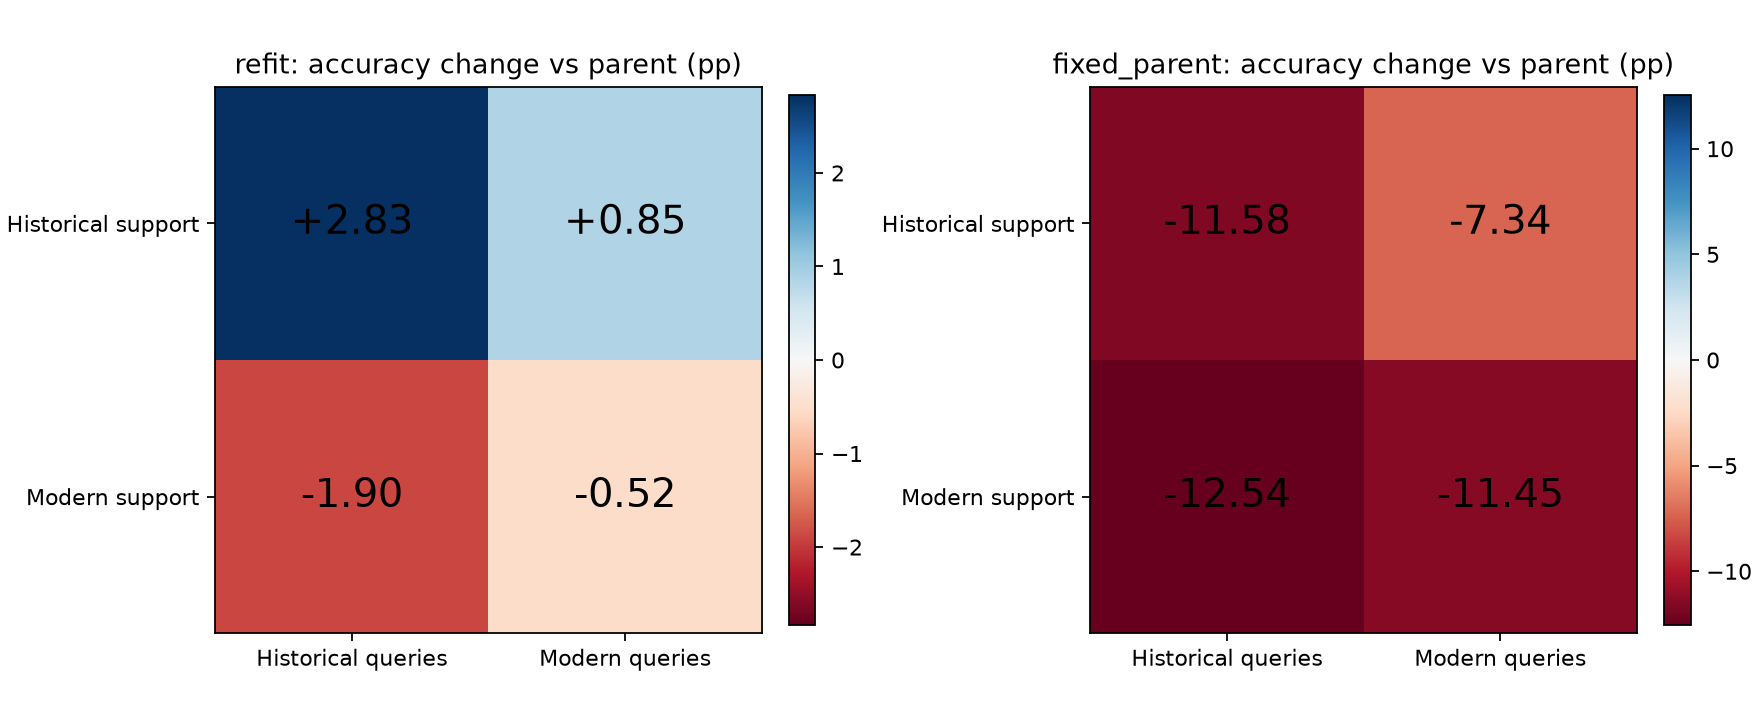

In [1]:
from pathlib import Path
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\audit-transfer\\20261103-n138-r1\\crossed-primary.png'))


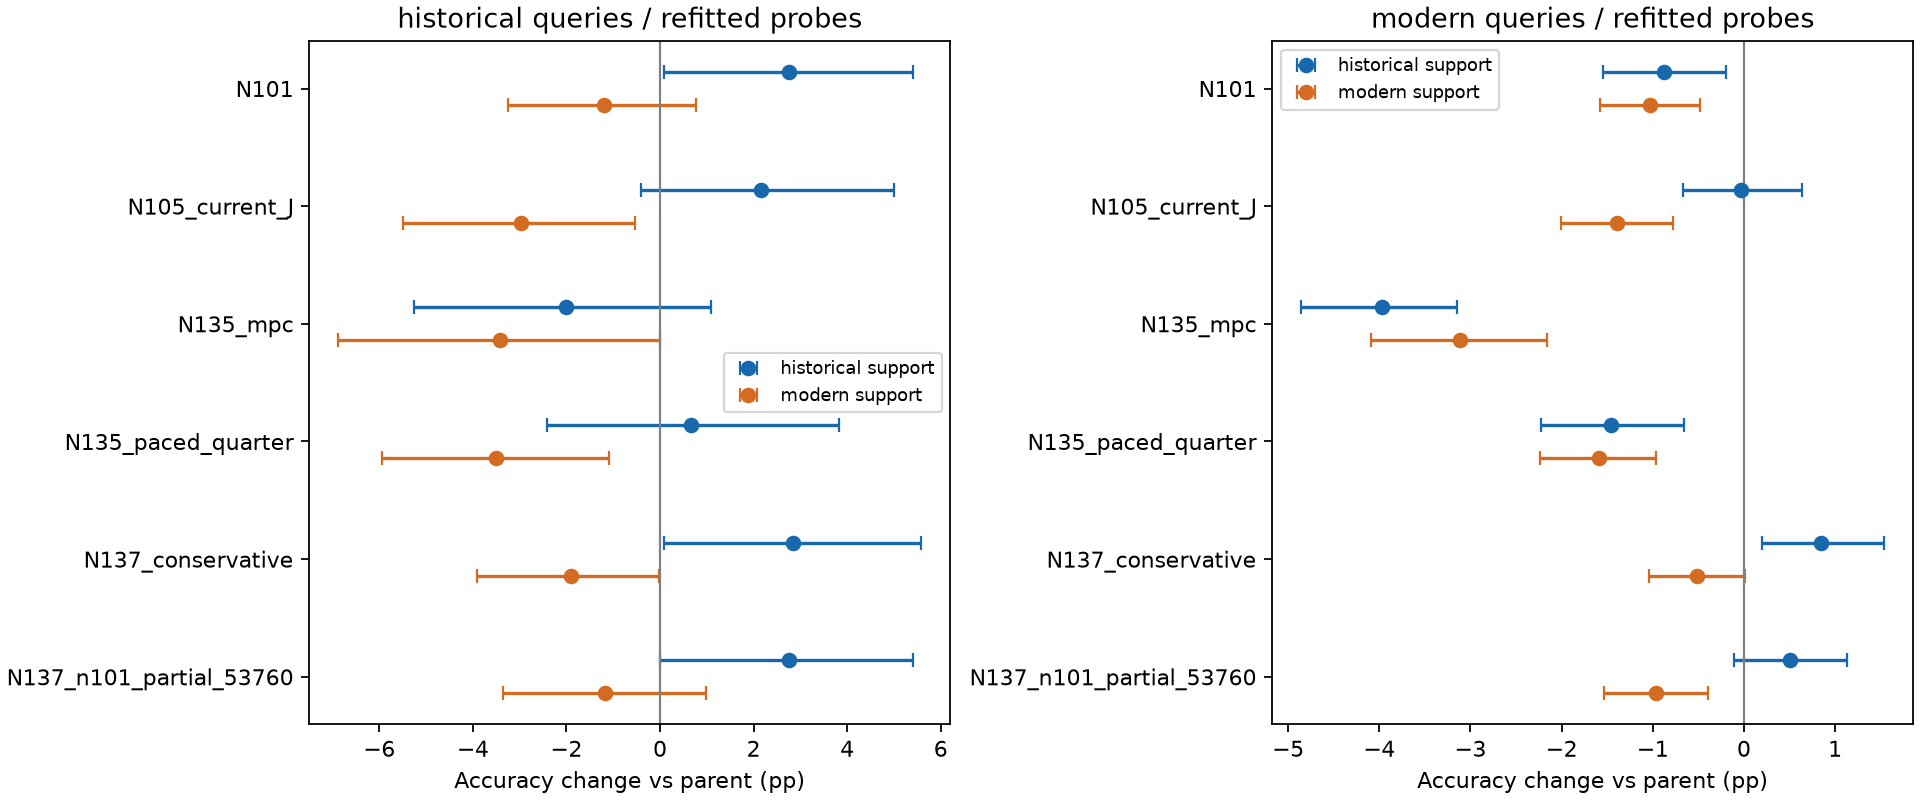

In [2]:
from pathlib import Path
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\audit-transfer\\20261103-n138-r1\\all-models.png'))


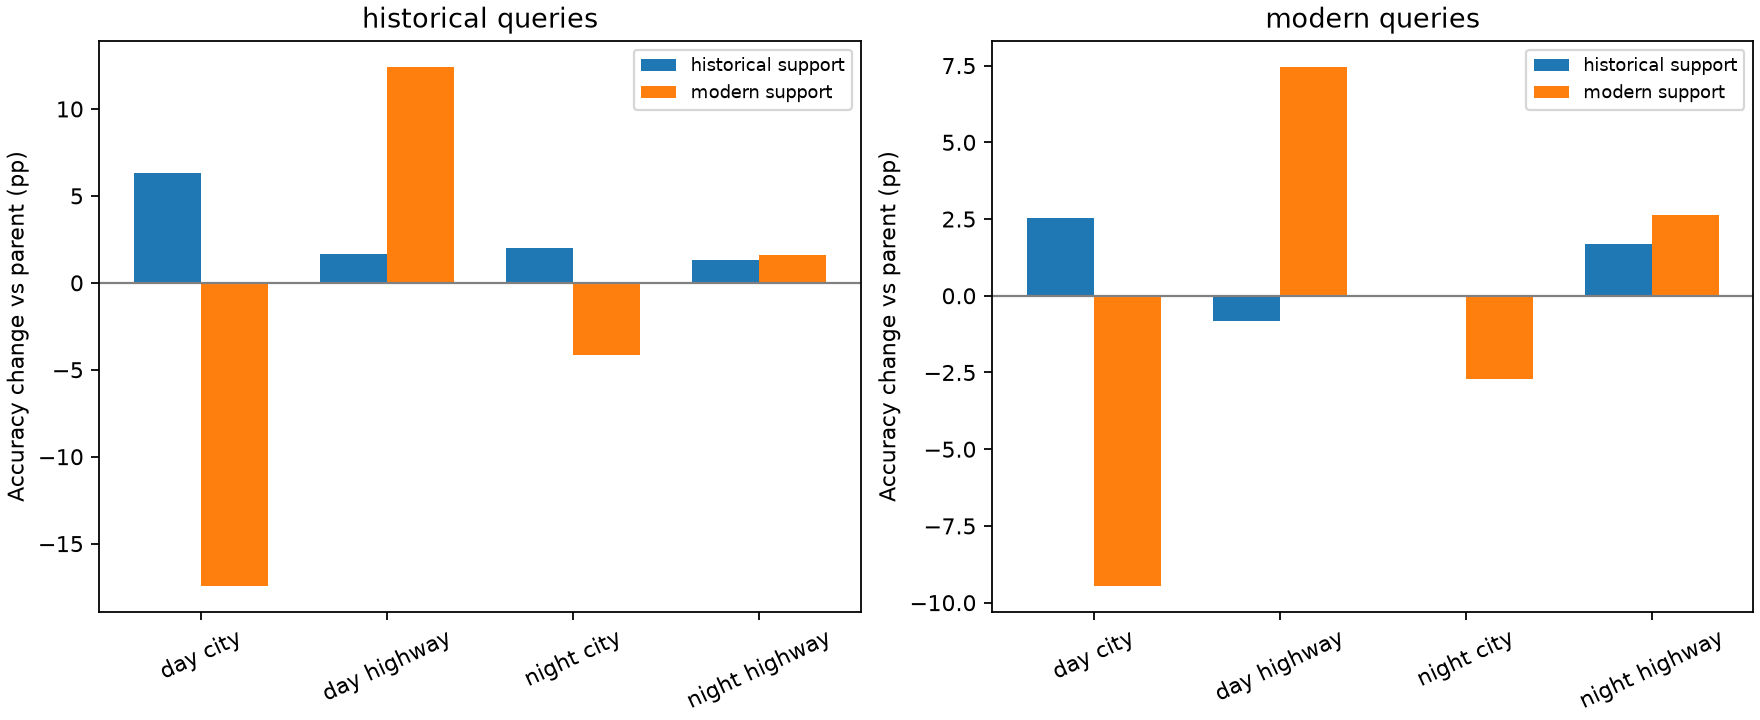

In [3]:
from pathlib import Path
from IPython.display import Image, display
display(Image(filename='C:\\CAFL-E\\project\\cafl4ds\\outputs\\audit-transfer\\20261103-n138-r1\\primary-cells.png'))


In [4]:
import json
RUN=Path('C:\\CAFL-E\\project\\cafl4ds\\outputs\\audit-transfer\\20261103-n138-r1')
print(json.dumps(json.loads((RUN/'paired-uncertainty.json').read_text()).get('N137_conservative',{}),indent=2))


{
  "refit__historical__historical": {
    "all": {
      "accuracy_delta_pp": 2.833333333333334,
      "ce_delta": -0.21487001362846997,
      "accuracy_delta_ci95": [
        0.08333333333333348,
        5.583333333333334
      ],
      "ce_delta_ci95": [
        -0.3352891681091474,
        -0.11621917260165286
      ],
      "cells_accuracy_delta_ci95": [
        [
          1.3333333333333348,
          11.666666666666668
        ],
        [
          -2.9999999999999987,
          6.333333333333335
        ],
        [
          -3.333333333333335,
          6.999999999999999
        ],
        [
          -5.333333333333334,
          7.333333333333335
        ]
      ]
    }
  },
  "refit__modern__historical": {
    "all": {
      "accuracy_delta_pp": -1.895833333333331,
      "ce_delta": -0.11978267780303191,
      "accuracy_delta_ci95": [
        -3.916666666666666,
        -0.02083333333333314
      ],
      "ce_delta_ci95": [
        -0.20535108370935204,
        -0.046879